## 1. 경로 설정 및 원본 로딩

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATASET_KEY = "서울시 자치구별 도보 네트워크 공간정보"
SOURCE_PREFIX = "서울시 자치구별 도보 네트워크 공간정보"

def find_repo():
    cwd = Path.cwd().resolve()
    for current in [cwd, *cwd.parents]:
        if current.name == "do_not_lung" and (current / "notebooks").exists():
            return current
        candidate = current / "do_not_lung"
        if (candidate / "notebooks").exists():
            return candidate
    raise FileNotFoundError("do_not_lung 저장소를 찾을 수 없습니다.")

REPO = find_repo()
DATA_ROOT = REPO.parent / "data"
RAW_ROOT = DATA_ROOT / "raw_data"
OUT_DIR = DATA_ROOT / "processed_data" / DATASET_KEY
candidates = sorted(RAW_ROOT.rglob(SOURCE_PREFIX + "*.csv"), key=lambda p: (p.name != SOURCE_PREFIX + ".csv", str(p)))
if not candidates:
    raise FileNotFoundError(f"원본 CSV를 찾지 못했습니다: {RAW_ROOT}")
RAW_PATH = candidates[0]
for enc in ("cp949", "euc-kr", "utf-8-sig"):
    try:
        pd.read_csv(RAW_PATH, encoding=enc, nrows=5)
        break
    except (UnicodeDecodeError, UnicodeError):
        continue
else:
    raise UnicodeError("CSV 인코딩을 판별할 수 없습니다.")

chunks = []
source_rows = 0
source_cols = None
for chunk in pd.read_csv(RAW_PATH, encoding=enc, dtype="string", chunksize=50000, low_memory=False):
    if source_cols is None:
        source_cols = chunk.columns.tolist()
        must = {"노드링크 유형", "노드 WKT", "노드 ID", "링크 WKT", "링크 ID", "시작노드 ID", "종료노드 ID", "링크 길이", "시군구코드", "시군구명"}
        if missing := must - set(source_cols):
            raise ValueError(f"필수 컬럼이 없습니다: {missing}")
    row_ids = np.arange(source_rows + 1, source_rows + 1 + len(chunk))
    matched = chunk["시군구명"].str.strip().eq("강남구").fillna(False)
    one = chunk.loc[matched].copy()
    if len(one):
        one.insert(0, "source_row_id", row_ids[matched.to_numpy(dtype=bool)])
        chunks.append(one)
    source_rows += len(chunk)
if not chunks:
    raise ValueError("강남구 데이터가 없습니다.")
raw_gangnam = pd.concat(chunks, ignore_index=True)
print("원본 파일:", RAW_PATH.name, "| 인코딩:", enc)
print("서울 전체:", source_rows, "행 ×", len(source_cols), "열")
print("강남구:", len(raw_gangnam), "행 ×", len(source_cols), "원본 열")
print("메모리 MB:", round(raw_gangnam.memory_usage(deep=True).sum()/1024**2, 2))
print("pandas:", pd.__version__)
display(raw_gangnam.head())
display(raw_gangnam.dtypes.to_frame("dtype"))

원본 파일: 서울시 자치구별 도보 네트워크 공간정보.csv | 인코딩: cp949
서울 전체: 491082 행 × 23 열
강남구: 29134 행 × 23 원본 열
메모리 MB: 37.82
pandas: 3.0.6


,source_row_id,노드링크 유형,노드 WKT,노드 ID,노드 유형 코드,링크 WKT,링크 ID,링크 유형 코드,시작노드 ID,종료노드 ID,...,읍면동명,고가도로,지하철네트워크,교량,터널,육교,횡단보도,"공원,녹지",건물내,수집일자
0,420896,NODE,POINT(127.02006014136082 37.52376153734316),204537,0,<NA>,0,<NA>,<NA>,<NA>,...,압구정동,<NA>,<NA>,<NA>,<NA>,0,0,<NA>,<NA>,2026-11-02 14:41:05.0
1,420897,NODE,POINT(127.0804372397065 37.484789987352606),122570,0,<NA>,0,<NA>,<NA>,<NA>,...,일원동,<NA>,<NA>,<NA>,<NA>,0,1,<NA>,<NA>,2026-11-02 14:40:11.0
2,420898,NODE,POINT(127.0806037897218 37.484771565359296),122571,0,<NA>,0,<NA>,<NA>,<NA>,...,일원동,<NA>,<NA>,<NA>,<NA>,0,0,<NA>,<NA>,2026-11-02 14:40:11.0
3,420899,NODE,POINT(127.08135103954672 37.485285979381615),122572,0,<NA>,0,<NA>,<NA>,<NA>,...,일원동,<NA>,<NA>,<NA>,<NA>,0,0,<NA>,<NA>,2026-11-02 14:40:11.0
4,420900,NODE,POINT(127.08257950415651 37.48463746443843),122573,0,<NA>,0,<NA>,<NA>,<NA>,...,일원동,<NA>,<NA>,<NA>,<NA>,0,0,<NA>,<NA>,2026-11-02 14:40:11.0


,dtype
source_row_id,int64
노드링크 유형,string
노드 WKT,string
노드 ID,string
노드 유형 코드,string
링크 WKT,string
링크 ID,string
링크 유형 코드,string
시작노드 ID,string
종료노드 ID,string


## 2. 구조·결측·품질 점검

In [2]:
clean = raw_gangnam.copy()
for col in source_cols:
    clean[col] = clean[col].str.strip().replace("", pd.NA)
for col in ("링크 길이",):
    clean[col] = pd.to_numeric(clean[col], errors="coerce")
clean["수집일자"] = pd.to_datetime(clean["수집일자"], errors="coerce").dt.strftime("%Y-%m-%d %H:%M:%S")

is_node = clean["노드링크 유형"].eq("NODE").fillna(False)
is_link = clean["노드링크 유형"].eq("LINK").fillna(False)
node_ids = set(clean.loc[is_node, "노드 ID"].dropna())
links = clean.loc[is_link]
nodes = clean.loc[is_node]

clean["node_wkt_valid"] = (~is_node | clean["노드 WKT"].str.startswith("POINT(", na=False)).astype(bool)
clean["link_wkt_valid"] = (~is_link | clean["링크 WKT"].str.startswith("LINESTRING(", na=False)).astype(bool)
clean["link_length_positive"] = (~is_link | clean["링크 길이"].gt(0).fillna(False)).astype(bool)
clean["duplicate_node_id_flag"] = (is_node & clean.loc[:, "노드 ID"].duplicated(keep=False) & clean["노드 ID"].notna()).astype(bool)
clean["duplicate_link_id_flag"] = (is_link & clean.loc[:, "링크 ID"].duplicated(keep=False) & clean["링크 ID"].notna()).astype(bool)
clean["duplicate_full_row_flag"] = raw_gangnam.duplicated(subset=source_cols, keep=False)
clean["start_node_outside_extract"] = (is_link & ~clean["시작노드 ID"].isin(node_ids)).astype(bool)
clean["end_node_outside_extract"] = (is_link & ~clean["종료노드 ID"].isin(node_ids)).astype(bool)
clean["boundary_reference_review"] = clean["start_node_outside_extract"] | clean["end_node_outside_extract"]
clean["review_needed"] = (
    ~clean["node_wkt_valid"] | ~clean["link_wkt_valid"] | ~clean["link_length_positive"]
    | clean["duplicate_node_id_flag"] | clean["duplicate_link_id_flag"] | clean["duplicate_full_row_flag"]
    | clean["boundary_reference_review"] | clean["수집일자"].isna()
)
# 다른 구의 노드를 참조할 수 있으므로 경계 링크는 절대 자동 삭제하지 않음.
missing = pd.DataFrame({"missing_count":clean[source_cols].isna().sum(),
                        "missing_pct":clean[source_cols].isna().mean()*100})
print("노드:", int(is_node.sum()), "링크:", int(is_link.sum()))
print("고유 노드 ID:", nodes["노드 ID"].nunique(), "고유 링크 ID:", links["링크 ID"].nunique())
print("시작노드 미매칭 참조:", int(clean["start_node_outside_extract"].sum()))
print("종료노드 미매칭 참조:", int(clean["end_node_outside_extract"].sum()))
print("경계 참조 검토 행:", int(clean["boundary_reference_review"].sum()))
print("완전 중복 행:", int(clean["duplicate_full_row_flag"].sum()))
print("검토 필요:", int(clean["review_needed"].sum()))
print("수집일시 범위:", clean["수집일자"].min(), "~", clean["수집일자"].max())
display(missing)
print("링크 길이(m) 기술통계")
display(clean.loc[is_link, "링크 길이"].describe())

노드: 12267 링크: 16867
고유 노드 ID: 12267 고유 링크 ID: 16867
시작노드 미매칭 참조: 171
종료노드 미매칭 참조: 243
경계 참조 검토 행: 391
완전 중복 행: 0
검토 필요: 391
수집일시 범위: 2026-11-02 14:36:02 ~ 2026-11-02 14:41:14


,missing_count,missing_pct
노드링크 유형,0,0.000000
노드 WKT,16867,57.894556
노드 ID,0,0.000000
노드 유형 코드,16867,57.894556
링크 WKT,12267,42.105444
링크 ID,0,0.000000
링크 유형 코드,12267,42.105444
시작노드 ID,12267,42.105444
종료노드 ID,12267,42.105444
링크 길이,12267,42.105444


링크 길이(m) 기술통계


count      16867.0
mean     52.656738
std       57.64036
min          2.257
25%        21.5485
50%          38.26
75%        66.1205
max       1608.024
Name: 링크 길이, dtype: Float64

## 3. 링크 유형 및 물리적 특성 집계

In [3]:
flags = ["고가도로", "지하철네트워크", "교량", "터널", "육교", "횡단보도", "공원,녹지", "건물내"]
print("링크 유형")
display(clean.loc[is_link, "링크 유형 코드"].value_counts(dropna=False).to_frame("records"))
print("노드 유형")
display(clean.loc[is_node, "노드 유형 코드"].value_counts(dropna=False).to_frame("records"))
print("읍면동별 링크 수")
display(clean.loc[is_link, "읍면동명"].value_counts(dropna=False).head(30).to_frame("links"))
for c in flags:
    print(c, clean.loc[is_link,c].value_counts(dropna=False).to_dict())

링크 유형


,records
링크 유형 코드,
1111,12624
1011,3108
1000,1122
1100,6
0100,4
1010,3


노드 유형


,records
노드 유형 코드,
0,11732
2,529
3,6


읍면동별 링크 수


,links
읍면동명,
역삼동,2148
대치동,2103
논현동,1744
삼성동,1740
개포동,1726
일원동,1257
청담동,1078
도곡동,1038
신사동,957


고가도로 {'0': 16867}
지하철네트워크 {'0': 16867}
교량 {'0': 16849, '1': 18}
터널 {'0': 16862, '1': 5}
육교 {'0': 16864, '1': 3}
횡단보도 {'0': 15930, '1': 937}
공원,녹지 {'0': 16794, '1': 73}
건물내 {'0': 16111, '1': 756}


## 4. 위치 분포 및 길이 시각화

노드 좌표 유효: 12267 / 12267
경도 범위: 127.01265523127093 127.12189192883976
위도 범위: 37.45989643413196 37.53375731060043


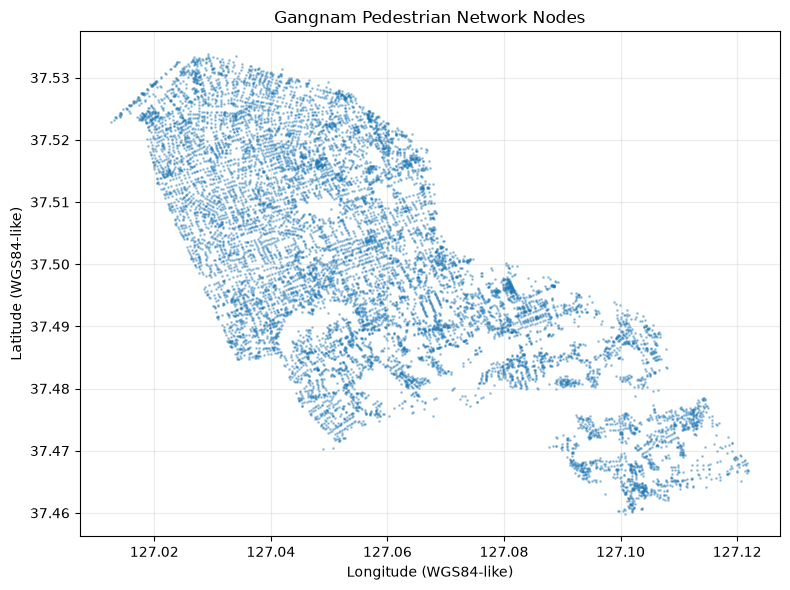

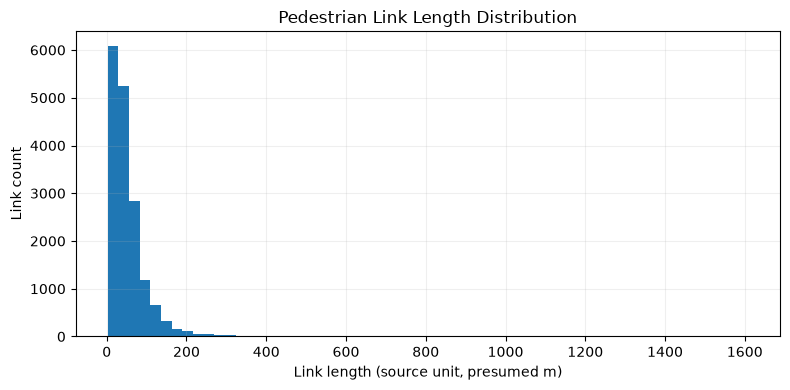

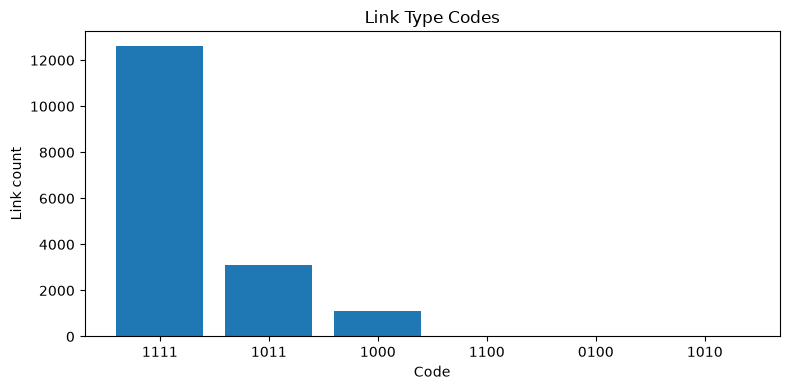

In [4]:
def node_coordinates(s):
    m = s.str.extract(r"^POINT\(\s*(-?\d+(?:\.\d+)?)\s+(-?\d+(?:\.\d+)?)\s*\)$")
    return pd.to_numeric(m[0], errors="coerce"), pd.to_numeric(m[1], errors="coerce")
node_rows = clean.loc[is_node].copy()
lon, lat = node_coordinates(node_rows["노드 WKT"])
node_rows["longitude"], node_rows["latitude"] = lon,lat
print("노드 좌표 유효:", int((lon.between(124,132)&lat.between(33,39)).sum()), "/",len(node_rows))
print("경도 범위:", lon.min(),lon.max())
print("위도 범위:", lat.min(),lat.max())
fig,ax=plt.subplots(figsize=(8,6))
ax.scatter(lon,lat,s=1,alpha=.35)
ax.set(title="Gangnam Pedestrian Network Nodes",xlabel="Longitude (WGS84-like)",ylabel="Latitude (WGS84-like)")
ax.grid(alpha=.25);plt.tight_layout();plt.show();plt.close(fig)
fig,ax=plt.subplots(figsize=(8,4))
ax.hist(clean.loc[is_link,"링크 길이"].dropna(),bins=60)
ax.set(title="Pedestrian Link Length Distribution",xlabel="Link length (source unit, presumed m)",ylabel="Link count")
ax.grid(alpha=.2);plt.tight_layout();plt.show();plt.close(fig)
counts=clean.loc[is_link,"링크 유형 코드"].value_counts().head(12)
fig,ax=plt.subplots(figsize=(8,4))
ax.bar(counts.index.astype(str),counts.values)
ax.set(title="Link Type Codes",xlabel="Code",ylabel="Link count")
plt.tight_layout();plt.show();plt.close(fig)

## 5. features.csv 및 summary.csv 생성

In [5]:
link_rows=clean.loc[is_link].copy()
features=link_rows[[
    "source_row_id","링크 ID","시작노드 ID","종료노드 ID","링크 WKT","링크 길이",
    "링크 유형 코드","시군구코드","읍면동코드","읍면동명",
    *flags,"start_node_outside_extract","end_node_outside_extract",
    "boundary_reference_review","link_wkt_valid","link_length_positive","review_needed"
]].rename(columns={"링크 ID":"link_id","시작노드 ID":"start_node_id","종료노드 ID":"end_node_id",
                   "링크 WKT":"link_wkt","링크 길이":"length_m","링크 유형 코드":"link_type_code"})
for c in flags:
    features["flag_"+{"고가도로":"elevated","지하철네트워크":"subway","교량":"bridge","터널":"tunnel",
                       "육교":"overpass","횡단보도":"crosswalk","공원,녹지":"park_green","건물내":"indoors"}[c]] = features[c].map({"1":1,"0":0}).astype("Int64")
# 250m 격자·흡연 위험 점수·정답 라벨은 임의로 생성하지 않음.
rows=[]
def add(section,metric,category,value,unit=""):
    rows.append({"section":section,"metric":metric,"category":category,"value":value,"unit":unit})
for k,v in {
    "source_rows":source_rows,"gangnam_rows":len(clean),"node_rows":int(is_node.sum()),
    "link_rows":int(is_link.sum()),"unique_node_ids":nodes["노드 ID"].nunique(),
    "unique_link_ids":links["링크 ID"].nunique(),
    "outside_start_refs":int(clean["start_node_outside_extract"].sum()),
    "outside_end_refs":int(clean["end_node_outside_extract"].sum()),
    "boundary_reference_review_rows":int(clean["boundary_reference_review"].sum()),
    "duplicate_full_rows":int(clean["duplicate_full_row_flag"].sum()),
    "review_needed_rows":int(clean["review_needed"].sum())}.items():add("overall",k,"",v,"rows")
for col in source_cols:
    add("missing","count",col,int(clean[col].isna().sum()),"rows")
    add("missing","percent",col,float(clean[col].isna().mean()*100),"%")
for col,label in (("링크 유형 코드","link_type"),("노드 유형 코드","node_type"),("읍면동명","dong")):
    subset = is_node if label=="node_type" else is_link
    for key,count in clean.loc[subset,col].value_counts(dropna=False).items():
        add(label,"records",str(key),int(count),"rows")
for flag in flags:
    add("link_flags","flag_equals_1",flag,int(clean.loc[is_link,flag].eq("1").sum()),"links")
for stat in ("min","max","mean","median","std"):
    add("link_length",stat,"링크 길이",float(getattr(clean.loc[is_link,"링크 길이"],stat)()),"source length unit")
summary=pd.DataFrame(rows)
print("clean:",clean.shape,"summary:",summary.shape,"features:",features.shape)
display(summary.head());display(features.head())

clean: (29134, 34) summary: (96, 5) features: (16867, 32)


,section,metric,category,value,unit
0,overall,source_rows,,491082.0,rows
1,overall,gangnam_rows,,29134.0,rows
2,overall,node_rows,,12267.0,rows
3,overall,link_rows,,16867.0,rows
4,overall,unique_node_ids,,12267.0,rows


,source_row_id,link_id,start_node_id,end_node_id,link_wkt,length_m,link_type_code,시군구코드,읍면동코드,읍면동명,...,link_length_positive,review_needed,flag_elevated,flag_subway,flag_bridge,flag_tunnel,flag_overpass,flag_crosswalk,flag_park_green,flag_indoors
30,420926,126209,127840,202161,"LINESTRING(127.10288 37.48134999999999,127.103...",18.9,1111,1168000000,1168011200,자곡동,...,True,False,0,0,0,0,0,0,0,0
31,420927,277925,131840,131858,LINESTRING(127.04509594050043 37.5019680773424...,108.187,1111,1168000000,1168010100,역삼동,...,True,False,0,0,0,0,0,0,0,0
33,420929,240087,26836,26835,LINESTRING(127.06724131297347 37.4941193694495...,18.004,1111,1168000000,1168010600,대치동,...,True,False,0,0,0,0,0,0,0,0
42,420938,157959,72782,72783,LINESTRING(127.04111032529171 37.4895973612597...,72.884,1111,1168000000,1168011800,도곡동,...,True,False,0,0,0,0,0,0,0,0
43,420939,157960,96495,96498,LINESTRING(127.10000000177415 37.4915489959374...,67.663,1111,1168000000,1168011500,수서동,...,True,False,0,0,0,0,0,0,0,0


## 6. CSV 저장 및 재읽기 검증

In [6]:
OUT_DIR.mkdir(parents=True, exist_ok=True)
outputs={"clean.csv":clean,"summary.csv":summary,"features.csv":features}
loaded={}
for name,frame in outputs.items():
    dest=OUT_DIR/name
    frame.to_csv(dest,index=False,encoding="utf-8-sig")
    reread=pd.read_csv(dest,encoding="utf-8-sig",dtype="string",low_memory=False)
    assert reread.shape==frame.shape, f"{name}: shape mismatch"
    assert list(reread.columns)==list(frame.columns),f"{name}: columns mismatch"
    assert dest.open("rb").read(3)==b"\xef\xbb\xbf",f"{name}: utf8 BOM absent"
    loaded[name]=reread
for name in ("clean.csv","features.csv"):
    assert loaded[name]["source_row_id"].tolist()==outputs[name]["source_row_id"].astype("string").tolist()
for c in ("노드 ID","링크 ID","시작노드 ID","종료노드 ID"):
    assert loaded["clean.csv"][c].fillna("").tolist()==clean[c].fillna("").tolist()
numeric=pd.to_numeric(loaded["features.csv"]["length_m"],errors="coerce").to_numpy(dtype=float)
assert np.allclose(numeric,features["length_m"].to_numpy(dtype=float),atol=1e-8,rtol=0,equal_nan=True)
assert len(features)==int(is_link.sum())
print("CSV 3개 저장·재읽기 검증 성공")

CSV 3개 저장·재읽기 검증 성공


## 7. README.md 생성 및 검증

In [7]:
base_desc={
    "source_row_id":"서울 원본 CSV 행 번호(1부터 시작)",
    "노드링크 유형":"NODE 또는 LINK 구분",
    "노드 WKT":"노드 POINT(x y) 형상 문자열",
    "노드 ID":"노드 고유 식별자",
    "노드 유형 코드":"원본 노드 유형 코드",
    "링크 WKT":"링크 LINESTRING(x y, ...) 형상 문자열",
    "링크 ID":"링크 고유 식별자",
    "링크 유형 코드":"원본 링크 유형 코드(코드 정의서 참조)",
    "시작노드 ID":"연결 링크의 출발 노드 ID",
    "종료노드 ID":"연결 링크의 도착 노드 ID",
    "링크 길이":"원본 링크 길이(거리 단위는 정의서 확인 필요)",
    "시군구코드":"시군구 코드",
    "시군구명":"시군구명(강남구만 추출)",
    "읍면동코드":"읍면동 코드",
    "읍면동명":"읍면동 명칭",
    "수집일자":"데이터 수집 시각",
    "node_wkt_valid":"NODE 행의 POINT WKT 형태 검사 결과",
    "link_wkt_valid":"LINK 행의 LINESTRING WKT 형태 검사 결과",
    "link_length_positive":"LINK 행의 양수 길이 검사 결과",
    "duplicate_node_id_flag":"NODE 행에서 노드 ID 중복 여부",
    "duplicate_link_id_flag":"LINK 행에서 링크 ID 중복 여부",
    "duplicate_full_row_flag":"원본 컬럼 전체 중복 여부",
    "start_node_outside_extract":"시작노드가 추출된 강남구 NODE에 없는 LINK",
    "end_node_outside_extract":"종료노드가 추출된 강남구 NODE에 없는 LINK",
    "boundary_reference_review":"시작 또는 종료 노드가 추출본에 없는 LINK",
    "review_needed":"품질 검토 플래그. 흡연 위험 점수 아님",
    "link_id":"원본 링크 ID",
    "start_node_id":"원본 시작노드 ID",
    "end_node_id":"원본 종료노드 ID",
    "link_wkt":"원본 링크 형상",
    "length_m":"원본 링크 길이 (미터 추정; 정의서 확인 필요)",
    "link_type_code":"원본 링크 유형 코드",
    "section":"통계 구분",
    "metric":"통계 지표",
    "category":"집계 범주",
    "value":"실제 계산한 통계값",
    "unit":"값의 단위",
    "고가도로":"고가도로 관련 원본 0/1 값",
    "지하철네트워크":"지하철네트워크 관련 원본 0/1 값",
    "교량":"교량 관련 원본 0/1 값",
    "터널":"터널 관련 원본 0/1 값",
    "육교":"육교 관련 원본 0/1 값",
    "횡단보도":"횡단보도 관련 원본 0/1 값",
    "공원,녹지":"공원·녹지 관련 원본 0/1 값",
    "건물내":"건물 내부 관련 원본 0/1 값"
}
for name in [c for c in features.columns if c.startswith("flag_")]:
    base_desc[name]="원본 링크 구조 특성을 0/1/결측으로 변환한 값; "+name
def escape(s):return str(s).replace("|","\\|").replace("\n"," ")
lines=["# 강남구 도보 네트워크 CSV 사용 설명서","","- 원본: `"+RAW_PATH.name+"`",
       "- 데이터 식별자: `"+DATASET_KEY+"`","- 추출: `시군구명=강남구`",
       "- 원본 인코딩: "+enc,"- 서울 전체 행 수: "+format(source_rows,","),
       "- 강남구 추출 행 수: "+format(len(clean),","),
       "- 원본 열 수: "+str(len(source_cols)),"",
       "## 전처리","","- NODE/LINK를 원래 형태로 보존하고 문자열 공백 및 수치형 링크 길이 표준화",
       "- NODE와 LINK 고유의 구조상 결측을 임의로 채우지 않음",
       "- 형상 형태·ID 중복·연결 참조 누락 검토 플래그 생성",
       "- 강남구 바깥 노드로 연결될 가능성이 있는 경계 링크는 제거하지 않음",
       "- 머신러닝 정답 라벨·흡연 위험 점수·250m 격자 ID를 생성하지 않음","",
       "## CSV별 설명",""]
purpose={"clean.csv":"원본 노드·링크를 보존한 정제 데이터","summary.csv":"구조·품질·링크 유형·동별 통계",
         "features.csv":"LINK 행 단위 경로 탐색·모델 입력변수 후보"}
for fn,frame in outputs.items():
    lines.extend([f"### {fn}","",f"- 목적: {purpose[fn]}",f"- 크기: {len(frame):,}행 × {len(frame.columns)}열","",
                  "| 컬럼명 | 자료형 | 의미 |","|---|---|---|"])
    for col in frame.columns:
        lines.append(f"| `{escape(col)}` | `{frame[col].dtype}` | {escape(base_desc.get(col,'원본 정보: 컬럼 정의서 확인 필요'))} |")
    lines.append("")
lines.extend(["## summary.csv 집계 기준","","- `overall`: 서울 전체·강남구 추출 규모, 노드·링크 수, 품질 검토",
              "- `missing`: 원본 컬럼별 결측 건수와 비율",
              "- `link_type`, `node_type`: 유형 코드별 행 수",
              "- `dong`: LINK 행을 기준으로 한 읍면동별 집계",
              "- `link_flags`: 구조 특성별 1인 링크 수",
              "- `link_length`: 링크 길이 기초통계","","## CSV 간 관계","",
              "- `clean.csv`: NODE와 LINK를 함께 보존한 전체 강남구 레코드",
              "- `features.csv`: LINK 행만 추출(연결 키: `source_row_id`, `link_id`)",
              "- `summary.csv`: 여러 집계 단위의 통계표로 원본과 1:1 병합 불가",
              "- 링크 연결은 `start_node_id`, `end_node_id`와 `clean.csv`의 NODE `노드 ID` 사용","",
              "## 사용 시 주의사항","",
              "- 강남구 소속 링크가 이웃 자치구 NODE를 참조할 수 있음; 전체 서울 노드로 연결 확인 필요",
              "- `boundary_reference_review`는 오류 확정이 아닌 검토 대상",
              "- WKT 좌표는 경위도 형태. 거리·면적 계산 시 투영좌표계 확인 필요",
              "- 링크 길이 단위는 별도 컬럼정의서로 확인 필요",
              "- 링크 유형 코드와 구조 플래그 해석은 원본 코드 정의서 필요",
              "- 보행 방향성, 통행 제한 및 실제 통행 가능성은 별도 검증 필요",
              "- 현재 파일만으로 250m 격자·흡연 발생·시간별 위험을 계산할 수 없음",
              "- 이 데이터의 NODE/LINK는 경로 탐색 그래프의 기반이며 흡연 관측 y가 아님",""])
readme=OUT_DIR/"README.md"
readme.write_text("\n".join(lines),encoding="utf-8")
rd=readme.read_text(encoding="utf-8")
for frame in outputs.values():
    for c in frame.columns:
        assert f"`{escape(c)}`" in rd
print("README 생성 및 검증 성공")

README 생성 및 검증 성공
